## 0.1. 全局参数配置

输入来源、起始帧、共用快门时间、仿真步长、0.3 ms 检测窗口、HVO₂ 模型、光电流映射、CMOS 固定放大器增益和电荷截断范围、脉冲累积器下限和上限、完成度分组和直方图分箱集中在下一单元。后续硬件模块读取这里的配置。


In [1]:
# 项目路径及所有实验可调参数集中在本单元。
from datetime import datetime
from decimal import Decimal
from importlib import reload
from pathlib import Path
import sys

import cv2
import numpy as np
from IPython.display import Image, display

_PROJECT_CANDIDATES = (Path.cwd(), Path.cwd() / "HVO2" / "neuron_model", Path.cwd() / "neuron_model")
PROJECT_DIR = next((p for p in _PROJECT_CANDIDATES if (p / "HDR_create.py").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Could not locate the HVO2 neuron_model project directory")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import HDR_create
import finite_oscillation_model
import intrinsic_vo2_model
import video_process
import shutter
import photodetector_model
import phase_array
import oscillation_detector
import array_readout
import readout_modules
import exposure_mapping
import notebook_viz
for _module in (
    HDR_create,
    finite_oscillation_model,
    intrinsic_vo2_model,
    video_process,
    shutter,
    photodetector_model,
    phase_array,
    oscillation_detector,
    array_readout,
    readout_modules,
    exposure_mapping,
    notebook_viz,
):
    reload(_module)

from finite_oscillation_model import ModelParameters
from video_process import PixelReactivationError, VideoPixelProcessor
from shutter import ShutterPlan
from photodetector_model import make_photocurrent_trace
from phase_array import run_hvo2_phase_array, run_intrinsic_vo2_phase_array
from oscillation_detector import detect_oscillation_windows
from array_readout import truncate_phase_windows
from readout_modules import (
    accumulate_phase_pulses,
    integrate_cmos_current_trace,
    map_cmos_charge,
)
from exposure_mapping import normalize_metric_map, select_completion_groups, write_completion_metric_images
from notebook_viz import display_histogram

# 输入来源: "synthetic_hdr" 使用第 0.2 节, "video" 使用 VIDEO_PATH。
INPUT_SOURCE = "synthetic_hdr"
VIDEO_PATH = PROJECT_DIR / "Weizmann_data" / "shahar_side.avi"
OUTPUT_ROOT = PROJECT_DIR / "outputs"

# 输入及共用快门: 起始帧按零起始索引; 视频当前沿用原流程的 50 fps 时间解释。
INPUT_START_FRAME = 0
VIDEO_SOURCE_FPS = 50.0
HDR_INPUT_FPS = 50.0
HDR_INPUT_DURATION_S = 1.0
VIDEO_CODE_MAX = 255.0
SHUTTER_WINDOWS_MS = (0.5, 1.0, 50.0)
SHUTTER_LABELS = ("underexposed", "moderate", "overexposed")

# 光电探测器模拟: PQ 码直接按既有概念演示线性映射; 视频使用 8-bit 亮度码。
PHOTODETECTOR_CURRENT_MIN_MA = 6.3
PHOTODETECTOR_CURRENT_MAX_MA = 7.5
PHOTODETECTOR_GAIN = 1.0
PHASE_INTEGRATION_DT_S = 1.0e-5

# HVO2 单器件拟合与电学参数。此结构保持 finite_oscillation_model 的现有默认值。
HVO2_MODEL_PARAMETERS = ModelParameters(
    reference_current_ma=7.32,
    reference_frequency_hz=21_643.2670724,
    frequency_slope_hz_per_ma=420.87232,
    minimum_frequency_hz=1.0,
    reference_strengthening_rate_per_s=75.76,
    strengthening_slope_per_s_per_ma=256.63,
    minimum_strengthening_rate_per_s=9.52,
    minimum_oscillation_current_ma=4.55,
    duration_curve_ms=finite_oscillation_model.fitted_oscillation_duration_ms,
    recovery_time_s=1.0,
    initial_high_resistance_ohm=2_000.0,
    initial_low_resistance_ohm=500.0,
    stopped_intermediate_resistance_ohm=1_100.0,
)

# OSCILLATION_DETECTOR_WINDOW_S检测窗口同时作开始延迟与停止确认延迟; 相位每步至少变化此值才视作活动。
OSCILLATION_DETECTOR_WINDOW_S = 0.1e-6
PHASE_CHANGE_TOLERANCE_RAD = 1.0e-12

# 脉冲累积器精度由上下限小数位数决定: 1710 为整数, 1710.0 为一位小数。
PULSE_ACCUMULATOR_MIN = 0.0
PULSE_ACCUMULATOR_MAX = 1070.0

# CMOS 单一放大器补偿系数，及器件电荷截断范围。
CMOS_AMPLIFIER_GAIN = 5e-12
CMOS_MIN_CHARGE_ELECTRONS = 10_500.0
CMOS_MAX_CHARGE_ELECTRONS = 12_500.0

# 图像映射、完成度输出、统计直方图和命名参数。
HVO2_COMPLETION_DIVISIONS = 4
HVO2_OUTPUT_METRICS = ("pulse_frequency",)
PULSE_HISTOGRAM_BINS = 10
CHARGE_HISTOGRAM_BINS = 10
INPUT_HISTOGRAM_BINS = 32
RESULT_TITLE = "HDR"

PROCESSOR = VideoPixelProcessor(
    fps=VIDEO_SOURCE_FPS,
    current_min_ma=PHOTODETECTOR_CURRENT_MIN_MA,
    current_max_ma=PHOTODETECTOR_CURRENT_MAX_MA,
    gain=PHOTODETECTOR_GAIN,
    simulation_dt_s=PHASE_INTEGRATION_DT_S,
    model_parameters=HVO2_MODEL_PARAMETERS,
)
if len(SHUTTER_WINDOWS_MS) != 3 or len(SHUTTER_LABELS) != 3:
    raise ValueError("请配置三档共用快门及对应标签")
print("实验参数已载入:", INPUT_SOURCE, "快门(ms)=", SHUTTER_WINDOWS_MS,
      "起始帧=", INPUT_START_FRAME, "积分步长(ms)=", PHASE_INTEGRATION_DT_S * 1000,
      "振荡检测窗(ms)=", OSCILLATION_DETECTOR_WINDOW_S * 1000,
      "脉冲范围=", (PULSE_ACCUMULATOR_MIN, PULSE_ACCUMULATOR_MAX),
      "CMOS增益=", CMOS_AMPLIFIER_GAIN,
      "CMOS电荷范围(e-)=",
      (CMOS_MIN_CHARGE_ELECTRONS, CMOS_MAX_CHARGE_ELECTRONS))


实验参数已载入: synthetic_hdr 快门(ms)= (0.5, 1.0, 50.0) 起始帧= 0 积分步长(ms)= 0.01 振荡检测窗(ms)= 9.999999999999999e-05 脉冲范围= (0.0, 1070.0) CMOS增益= 5e-12 CMOS电荷范围(e-)= (10500.0, 12500.0)


## 0.2. HDR 输入合成与直方图

本节模拟外界场景，不对应硬件。生成合成 HDR PQ 码值并显示输入直方图；预览图仍单独保存，其他 HDR 数据在内存中传递。


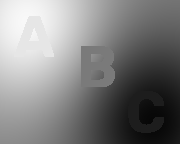

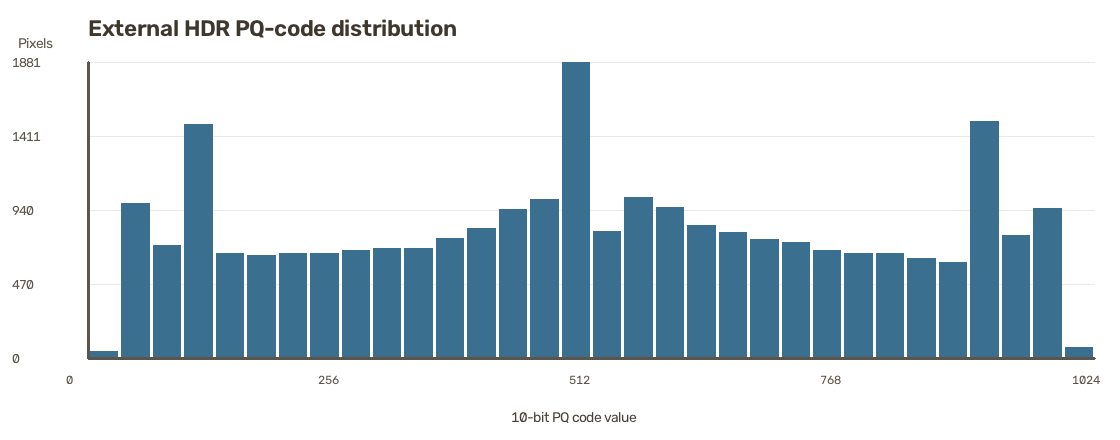

HDR 输入 shape=(50, 144, 180), PQ范围=28..995, 线性亮度=0.01634..7709.0 nit


In [2]:
SCENE_PQ_CODES = HDR_create.create_hdr10_test_matrix(PROJECT_DIR)
HDR_CODE_MAX = float(HDR_create.MAX_PQ_CODE)
HDR_SCENE_FRAMES = np.repeat(
    SCENE_PQ_CODES[np.newaxis, :, :],
    int(np.ceil(HDR_INPUT_FPS * HDR_INPUT_DURATION_S)),
    axis=0,
)
HDR_LINEAR_LUMINANCE_NITS = HDR_create.pq_decode_codes(SCENE_PQ_CODES)

display(Image(filename=str(PROJECT_DIR / HDR_create.PREVIEW_IMAGE_PATH.name)))
hdr_input_histogram = display_histogram(
    SCENE_PQ_CODES,
    bins=INPUT_HISTOGRAM_BINS,
    title="External HDR PQ-code distribution",
    x_label="10-bit PQ code value",
    value_range=(0, HDR_CODE_MAX + 1),
)
print(f"HDR 输入 shape={HDR_SCENE_FRAMES.shape}, PQ范围={SCENE_PQ_CODES.min()}..{SCENE_PQ_CODES.max()}, "
      f"线性亮度={HDR_LINEAR_LUMINANCE_NITS.min():.5f}..{HDR_LINEAR_LUMINANCE_NITS.max():.1f} nit")


## 1. 快门

快门按照全局起始帧和三档共用曝光窗口截取外界场景。HVO₂、本征 VO₂ 与 CMOS 使用同一组 5/10/90 ms 参数；本节只定义门控时间，不生成像素电流。


In [3]:
SHUTTER_PLAN = ShutterPlan(
    start_frame=INPUT_START_FRAME,
    frame_rate_hz=HDR_INPUT_FPS if INPUT_SOURCE == "synthetic_hdr" else VIDEO_SOURCE_FPS,
    exposure_windows_ms=SHUTTER_WINDOWS_MS,
)
_RESULT_TIMESTAMP = datetime.now().strftime("%m-%d-%H-%M-%S-%f")
RESULT_BUNDLE_DIR = OUTPUT_ROOT / f"{_RESULT_TIMESTAMP}-{RESULT_TITLE}"
HVO2_OUTPUT_DIR = RESULT_BUNDLE_DIR / "HVO2-output"
INTRINSIC_VO2_OUTPUT_DIR = RESULT_BUNDLE_DIR / "intrinsic-VO2-output"
TRADITIONAL_OUTPUT_DIR = RESULT_BUNDLE_DIR / "traditional-output"
for _output_dir in (HVO2_OUTPUT_DIR, INTRINSIC_VO2_OUTPUT_DIR, TRADITIONAL_OUTPUT_DIR):
    _output_dir.mkdir(parents=True, exist_ok=True)
print("快门三档:", SHUTTER_WINDOWS_MS, "ms; 起始帧:", INPUT_START_FRAME)
print("本次结果目录:", RESULT_BUNDLE_DIR)


快门三档: (0.5, 1.0, 50.0) ms; 起始帧: 0
本次结果目录: e:\vscode\HVO2\neuron_model\outputs\10-29-14-20-02-380793-HDR


## 2. 光电探测器阵列（Photodetector Array）

按设置的视频文件或合成场景读取亮度，裁到最长共用快门范围后映射为电流。输出只覆盖实际快门及检测器确认所需的尾段，不再把原始 1 秒重复输入整体送入阵列。


In [4]:
if INPUT_SOURCE == "synthetic_hdr":
    EXTERNAL_SCENE_FRAMES = HDR_SCENE_FRAMES
    SCENE_CODE_MAX = HDR_CODE_MAX
    SCENE_SOURCE_FPS = HDR_INPUT_FPS
elif INPUT_SOURCE == "video":
    EXTERNAL_SCENE_FRAMES = PROCESSOR.read_video_grayscale(VIDEO_PATH, start_frame=0)
    SCENE_CODE_MAX = VIDEO_CODE_MAX
    SCENE_SOURCE_FPS = VIDEO_SOURCE_FPS
else:
    raise ValueError("INPUT_SOURCE must be 'synthetic_hdr' or 'video'")

PHOTOCURRENT_TRACE = make_photocurrent_trace(
    EXTERNAL_SCENE_FRAMES,
    SHUTTER_PLAN,
    code_max=SCENE_CODE_MAX,
    current_min_ma=PHOTODETECTOR_CURRENT_MIN_MA,
    current_max_ma=PHOTODETECTOR_CURRENT_MAX_MA,
    gain=PHOTODETECTOR_GAIN,
    simulation_dt_s=PHASE_INTEGRATION_DT_S,
    detector_settle_s=OSCILLATION_DETECTOR_WINDOW_S,
)
print(f"光电流矩阵 (高,宽,时间)={PHOTOCURRENT_TRACE.current_ma.shape}; "
      f"采样时间={PHOTOCURRENT_TRACE.time_s[0]:.4f}..{PHOTOCURRENT_TRACE.time_s[-1]:.4f}s; "
      f"电流={PHOTOCURRENT_TRACE.current_ma.min():.4f}..{PHOTOCURRENT_TRACE.current_ma.max():.4f}mA")


光电流矩阵 (高,宽,时间)=(144, 180, 5006); 采样时间=0.0000..0.0500s; 电流=0.0000..7.4672mA


## 3.1. HVO₂ 阵列

按最长快门窗口积分快相位 θ。氢强化隐变量 h 在仿真中负责提前停止相位推进，但只输出时间分辨的 θ(H,W,T)；后面的检测器与脉冲累积器只读取相位轨迹。


In [5]:
HVO2_PHASE_ARRAY = run_hvo2_phase_array(PHOTOCURRENT_TRACE, HVO2_MODEL_PARAMETERS)
print("HVO₂ 相位矩阵:", HVO2_PHASE_ARRAY.shape,
      "最长窗口(s):", SHUTTER_PLAN.maximum_window_s)


HVO₂ 相位矩阵: (144, 180, 5006) 最长窗口(s): 0.05


## 3.2. 本征 VO₂ 阵列

只模拟一次最长快门相位轨迹，不设置隐变量 h、不会自行停振；各较短窗口通过快门边界截断同一轨迹并保持关闭后的相位不变。


In [6]:
INTRINSIC_VO2_PHASE_ARRAY = run_intrinsic_vo2_phase_array(
    PHOTOCURRENT_TRACE,
    HVO2_MODEL_PARAMETERS,
)
INTRINSIC_VO2_PHASE_WINDOWS = truncate_phase_windows(
    INTRINSIC_VO2_PHASE_ARRAY,
    PHOTOCURRENT_TRACE.time_s,
    SHUTTER_WINDOWS_MS,
    detector_window_s=OSCILLATION_DETECTOR_WINDOW_S,
)
print("本征 VO₂ 最长相位矩阵:", INTRINSIC_VO2_PHASE_ARRAY.shape,
      "三档矩阵:", {k: v[0].shape for k, v in INTRINSIC_VO2_PHASE_WINDOWS.items()})


本征 VO₂ 最长相位矩阵: (144, 180, 5006) 三档矩阵: {0.5: (144, 180, 52), 1.0: (144, 180, 103), 50.0: (144, 180, 5004)}


## 4. 振荡检测器阵列

每像素以相位变化表示信号活动。启动后连续满足 0.3 ms 才确认开启；末次相位变化后再等待 0.3 ms 确认关闭。计时以两个确认边沿之差得到，有效活动短于检测窗口的像素记为无有效输出。HVO₂ 一组；本征 VO₂ 按三档快门各读取一组。

In [7]:
HVO2_DETECTION = detect_oscillation_windows(
    HVO2_PHASE_ARRAY,
    PHOTOCURRENT_TRACE.time_s,
    detector_window_s=OSCILLATION_DETECTOR_WINDOW_S,
    phase_change_tolerance_rad=PHASE_CHANGE_TOLERANCE_RAD,
)
INTRINSIC_VO2_DETECTIONS = {
    window_ms: detect_oscillation_windows(
        phase_window,
        window_time,
        detector_window_s=OSCILLATION_DETECTOR_WINDOW_S,
        phase_change_tolerance_rad=PHASE_CHANGE_TOLERANCE_RAD,
    )
    for window_ms, (phase_window, window_time) in INTRINSIC_VO2_PHASE_WINDOWS.items()
}
print("HVO₂ 有效检测像素:", int(HVO2_DETECTION.active.sum()))
print("本征 VO₂ 三档有效检测像素:",
      {k: int(v.active.sum()) for k, v in INTRINSIC_VO2_DETECTIONS.items()})


HVO₂ 有效检测像素: 25920
本征 VO₂ 三档有效检测像素: {0.5: 25920, 1.0: 25920, 50.0: 25920}


## 5.1. 脉冲累积器

在检测器确认的有效振荡区间内读取相位差并换算成允许小数的脉冲数，超过 255.0 截断为 255.0。两种 VO₂ 共用同一上限。

In [8]:
HVO2_PULSE_COUNT_MAP = accumulate_phase_pulses(
    HVO2_PHASE_ARRAY,
    PHOTOCURRENT_TRACE.time_s,
    HVO2_DETECTION.start_time_s,
    HVO2_DETECTION.stop_time_s,
    HVO2_DETECTION.active,
    minimum_pulses=PULSE_ACCUMULATOR_MIN,
    maximum_pulses=PULSE_ACCUMULATOR_MAX,
)
INTRINSIC_VO2_PULSE_COUNT_MAPS = {
    window_ms: accumulate_phase_pulses(
        phase_window,
        window_time,
        INTRINSIC_VO2_DETECTIONS[window_ms].start_time_s,
        INTRINSIC_VO2_DETECTIONS[window_ms].stop_time_s,
        INTRINSIC_VO2_DETECTIONS[window_ms].active,
        minimum_pulses=PULSE_ACCUMULATOR_MIN,
        maximum_pulses=PULSE_ACCUMULATOR_MAX,
    )
    for window_ms, (phase_window, window_time) in INTRINSIC_VO2_PHASE_WINDOWS.items()
}
print("HVO₂ 脉冲数范围:", np.nanmin(HVO2_PULSE_COUNT_MAP), np.nanmax(HVO2_PULSE_COUNT_MAP))
print("本征 VO₂ 三档脉冲数范围:",
      {k: (np.nanmin(v), np.nanmax(v)) for k, v in INTRINSIC_VO2_PULSE_COUNT_MAPS.items()})


HVO₂ 脉冲数范围: 76.1 979.4
本征 VO₂ 三档脉冲数范围: {0.5: (np.float64(10.6), np.float64(10.8)), 1.0: (np.float64(21.2), np.float64(21.7)), 50.0: (np.float64(1061.3), np.float64(1070.0))}


## 5.2. CMOS

CMOS 使用 0.1 参数区给定的单一放大器增益积分共用光电流，并将电荷裁剪到配置的器件电荷范围。旧版光电转换参考式和逐档补偿系数计算不再使用。



In [9]:
CMOS_GAIN = float(CMOS_AMPLIFIER_GAIN)
if not np.isfinite(CMOS_GAIN) or CMOS_GAIN <= 0:
    raise ValueError("CMOS_AMPLIFIER_GAIN must be finite and positive")

CMOS_CHARGE_MAPS = integrate_cmos_current_trace(
    PHOTOCURRENT_TRACE,
    SHUTTER_WINDOWS_MS,
    amplifier_gain=CMOS_GAIN,
    minimum_charge_electrons=CMOS_MIN_CHARGE_ELECTRONS,
    maximum_charge_electrons=CMOS_MAX_CHARGE_ELECTRONS,
)
print(f"CMOS 单一放大器增益={CMOS_GAIN:.6g}")


CMOS 单一放大器增益=5e-12


## 6.1. 脉冲映射、统计与完成度分组

振荡频率 = 脉冲累积器读数 / 检测器计时时长。每张图内以有限频率的最小值和最大值映射 0–255。分别展示 HVO₂ 和本征 VO₂ 的频率、时长、脉冲数直方图；HVO₂ 仍按检测器完成时间保留前 25/50/75/100% 完成度结果图。

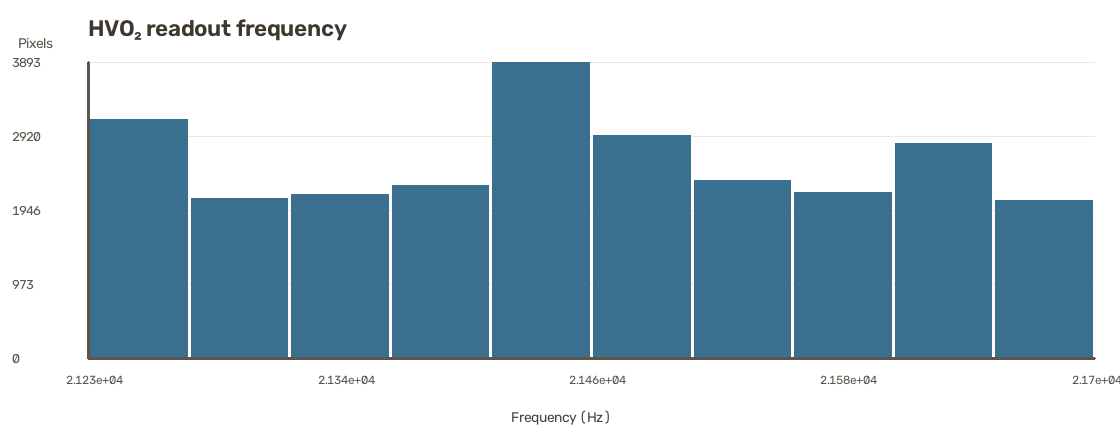

pulse_frequency: pixels=25920


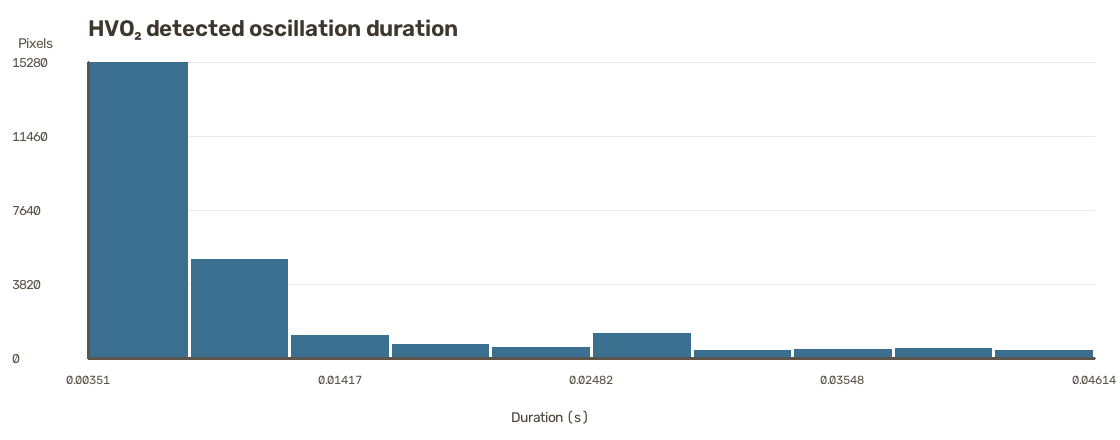

duration: pixels=25920


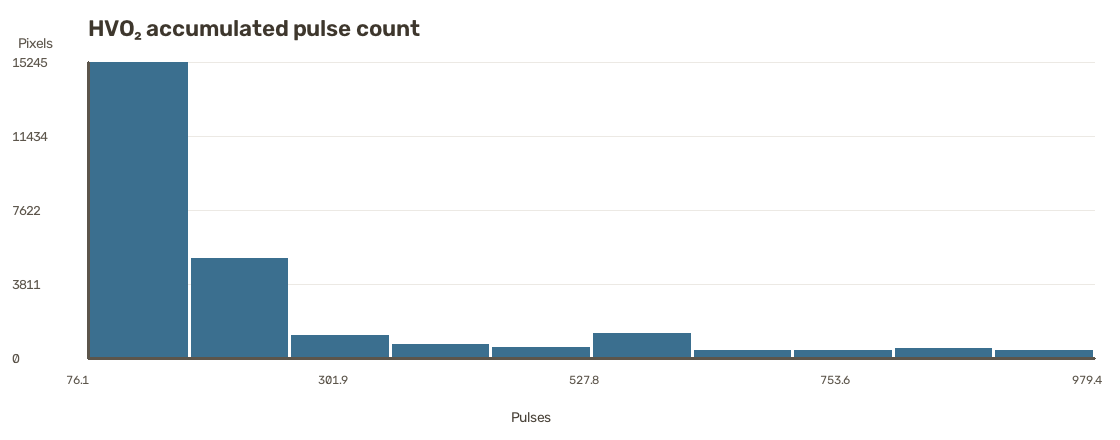

pulse_count: pixels=25920


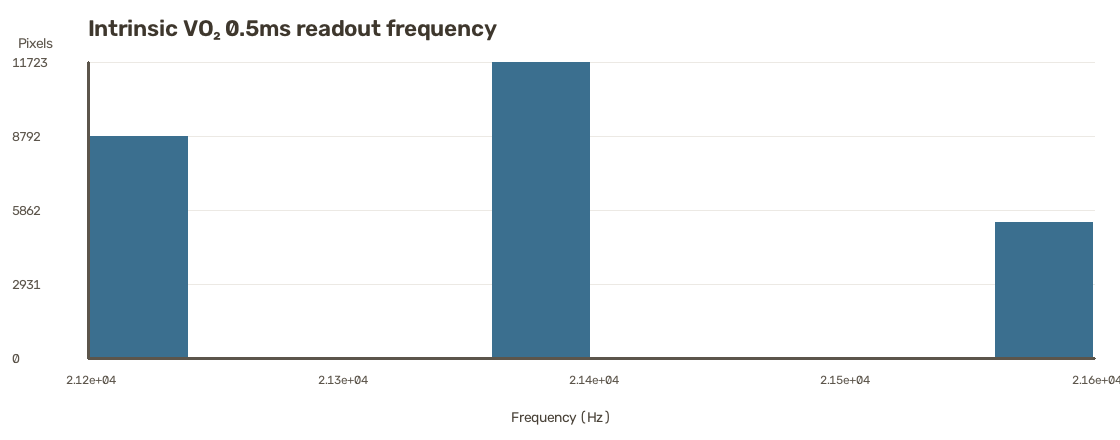

Intrinsic VO₂ 0.5ms: pixels=25920


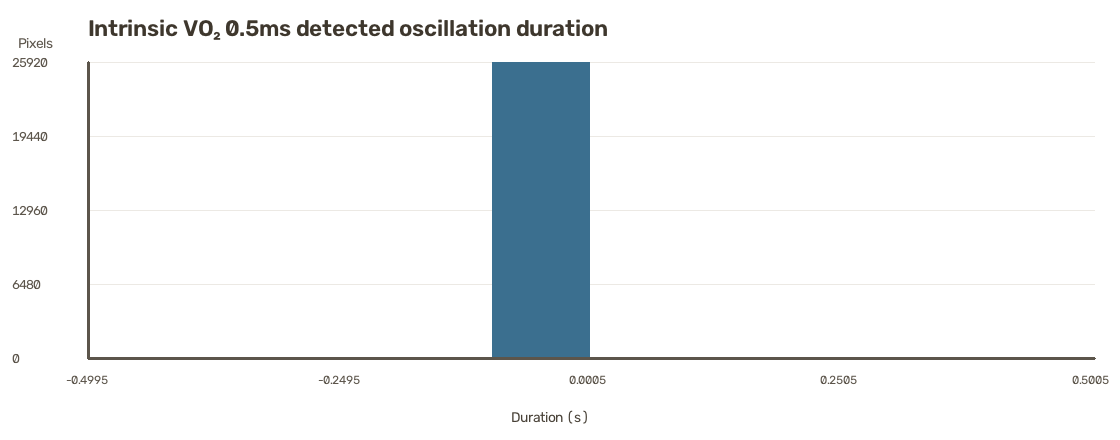

Intrinsic VO₂ 0.5ms: pixels=25920


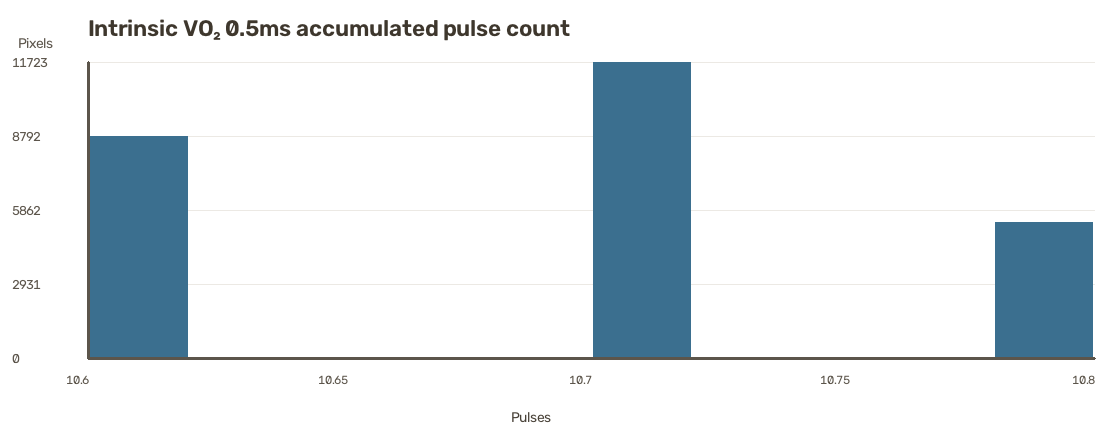

Intrinsic VO₂ 0.5ms: pixels=25920


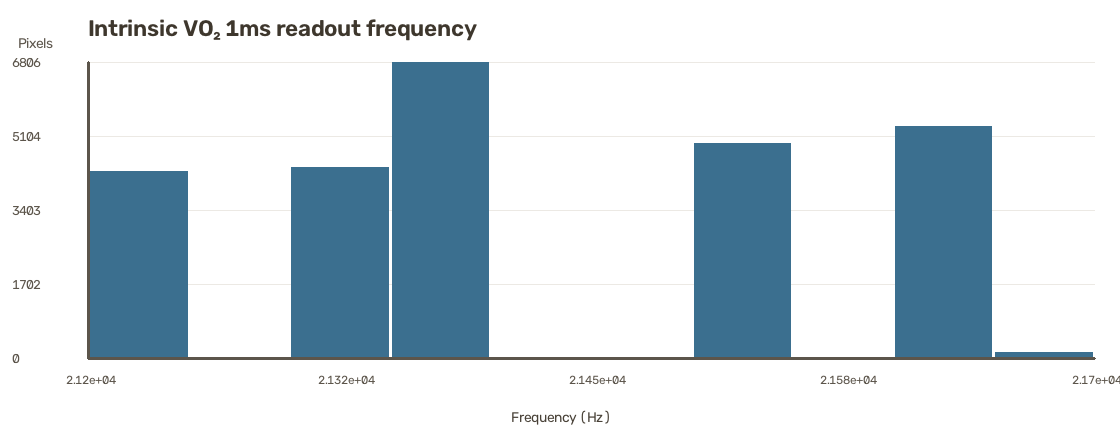

Intrinsic VO₂ 1ms: pixels=25920


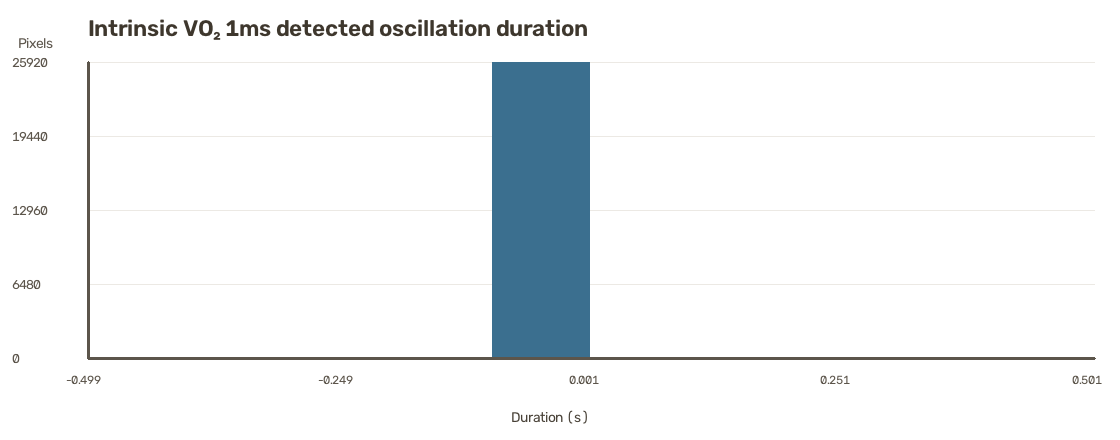

Intrinsic VO₂ 1ms: pixels=25920


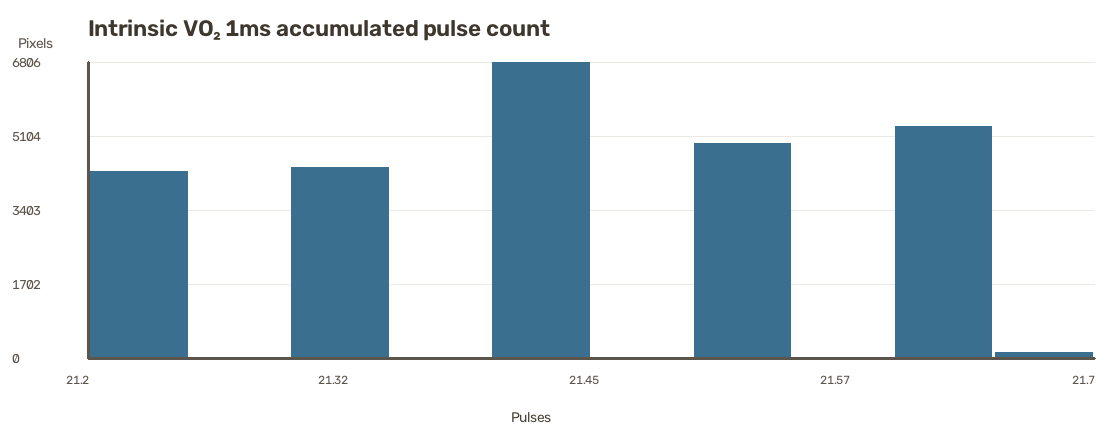

Intrinsic VO₂ 1ms: pixels=25920


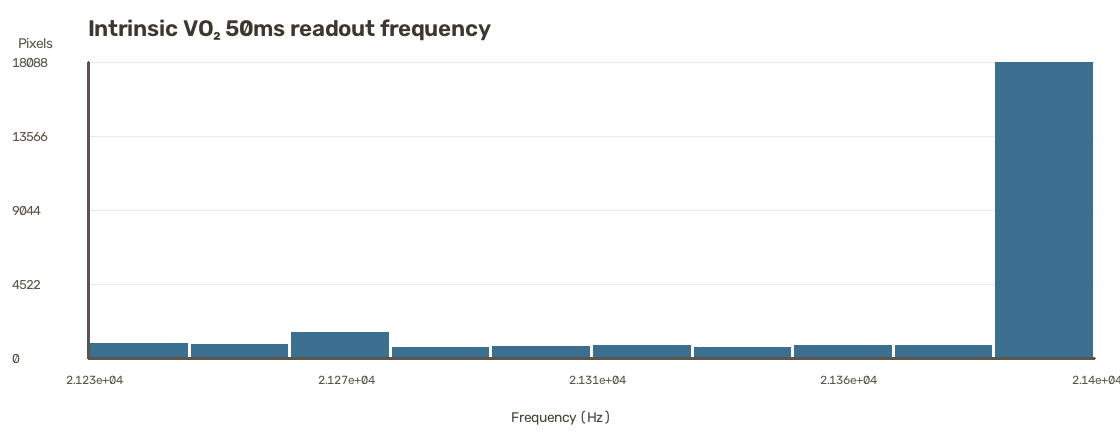

Intrinsic VO₂ 50ms: pixels=25920


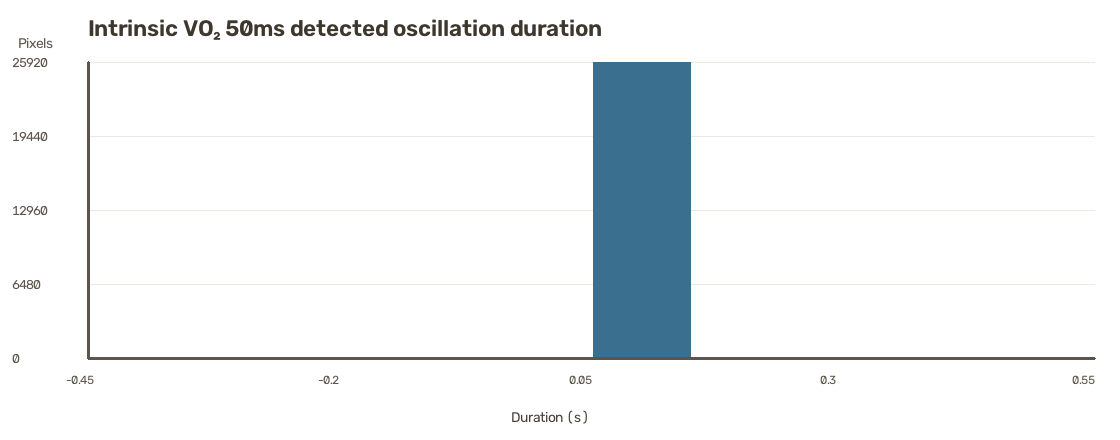

Intrinsic VO₂ 50ms: pixels=25920


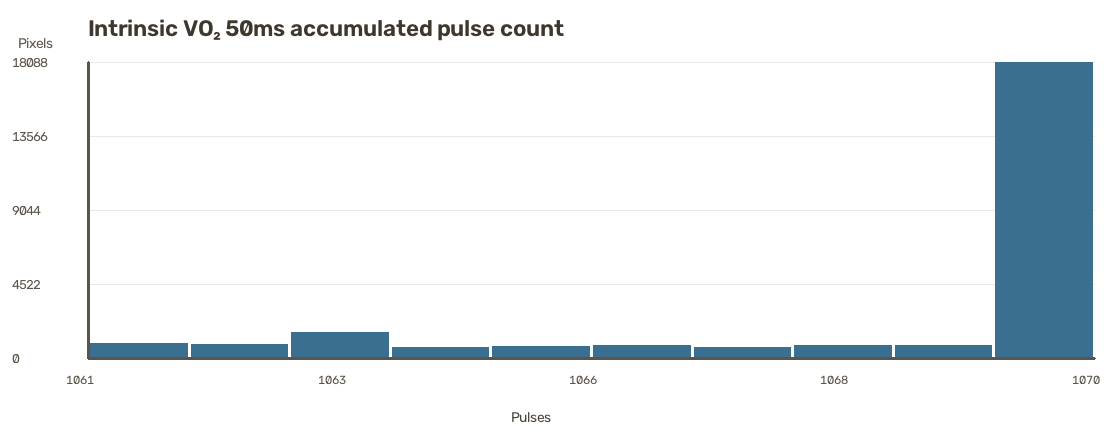

Intrinsic VO₂ 50ms: pixels=25920
频率图与完成度分组已保存: e:\vscode\HVO2\neuron_model\outputs\10-29-14-20-02-380793-HDR\HVO2-output e:\vscode\HVO2\neuron_model\outputs\10-29-14-20-02-380793-HDR\intrinsic-VO2-output


In [10]:
HVO2_DURATION_MAP_S = HVO2_DETECTION.duration_s
HVO2_FREQUENCY_MAP_HZ = np.divide(
    HVO2_PULSE_COUNT_MAP,
    HVO2_DURATION_MAP_S,
    out=np.full_like(HVO2_PULSE_COUNT_MAP, np.nan),
    where=np.isfinite(HVO2_DURATION_MAP_S) & (HVO2_DURATION_MAP_S > 0),
)
HVO2_METRIC_MAPS = {
    "pulse_frequency": HVO2_FREQUENCY_MAP_HZ,
    "duration": HVO2_DURATION_MAP_S,
    "pulse_count": HVO2_PULSE_COUNT_MAP,
}
HVO2_COMPLETION_TIME_MAP = np.where(
    HVO2_DETECTION.active,
    HVO2_DETECTION.stop_time_s,
    np.nan,
)

for _metric, _title, _xlabel in (
    ("pulse_frequency", "HVO₂ readout frequency", "Frequency (Hz)"),
    ("duration", "HVO₂ detected oscillation duration", "Duration (s)"),
    ("pulse_count", "HVO₂ accumulated pulse count", "Pulses"),
):
    _values = HVO2_METRIC_MAPS[_metric]
    _counts = display_histogram(
        _values[np.isfinite(_values)],
        bins=PULSE_HISTOGRAM_BINS,
        title=_title,
        x_label=_xlabel,
    )
    print(f"{_metric}: pixels={int(_counts.sum())}")

HVO2_COMPLETION_GROUPS = select_completion_groups(
    HVO2_COMPLETION_TIME_MAP,
    HVO2_COMPLETION_DIVISIONS,
)
INTRINSIC_VO2_FREQUENCY_MAPS_HZ = {}
for _window_ms, _pulse_map in INTRINSIC_VO2_PULSE_COUNT_MAPS.items():
    _duration_map = INTRINSIC_VO2_DETECTIONS[_window_ms].duration_s
    _frequency_map = np.divide(
        _pulse_map,
        _duration_map,
        out=np.full_like(_pulse_map, np.nan),
        where=np.isfinite(_duration_map) & (_duration_map > 0),
    )
    INTRINSIC_VO2_FREQUENCY_MAPS_HZ[_window_ms] = _frequency_map
    _prefix = f"Intrinsic VO₂ { _window_ms:g}ms"
    for _values, _title, _xlabel in (
        (_frequency_map, f"{_prefix} readout frequency", "Frequency (Hz)"),
        (_duration_map, f"{_prefix} detected oscillation duration", "Duration (s)"),
        (_pulse_map, f"{_prefix} accumulated pulse count", "Pulses"),
    ):
        _counts = display_histogram(
            _values[np.isfinite(_values)],
            bins=PULSE_HISTOGRAM_BINS,
            title=_title,
            x_label=_xlabel,
        )
        print(f"{_prefix}: pixels={int(_counts.sum())}")

if not HVO2_OUTPUT_METRICS:
    raise ValueError("HVO2_OUTPUT_METRICS must select at least one metric")
for _name in HVO2_OUTPUT_METRICS:
    if _name not in HVO2_METRIC_MAPS:
        raise ValueError(f"unsupported HVO2 output metric: {_name}")
for _percentage, _mask in HVO2_COMPLETION_GROUPS:
    write_completion_metric_images(
        HVO2_OUTPUT_DIR,
        _percentage,
        _mask,
        {name: HVO2_METRIC_MAPS[name] for name in HVO2_OUTPUT_METRICS},
    )
# 完成度分组之外，保留完整 HVO₂ 阵列的频率读出图。
HVO2_FREQUENCY_IMAGE = normalize_metric_map(HVO2_FREQUENCY_MAP_HZ)
HVO2_FREQUENCY_IMAGE_PATH = HVO2_OUTPUT_DIR / "hvo2-readout-frequency.png"
if not cv2.imwrite(str(HVO2_FREQUENCY_IMAGE_PATH), HVO2_FREQUENCY_IMAGE):
    raise OSError(f"failed to save HVO₂ frequency image: {HVO2_FREQUENCY_IMAGE_PATH}")

# 所有振荡频率图均在本板块映射与保存；统计直方图只在 notebook 内展示。
for _label, _window_ms in zip(SHUTTER_LABELS, SHUTTER_WINDOWS_MS):
    _frequency_map = INTRINSIC_VO2_FREQUENCY_MAPS_HZ[_window_ms]
    _image = normalize_metric_map(_frequency_map)
    _path = INTRINSIC_VO2_OUTPUT_DIR / f"intrinsic_vo2_{_label}_{_window_ms:g}ms.png"
    if not cv2.imwrite(str(_path), _image):
        raise OSError(f"failed to save intrinsic VO2 image: {_path}")
print("频率图与完成度分组已保存:", HVO2_OUTPUT_DIR, INTRINSIC_VO2_OUTPUT_DIR)


## 6.2. 电荷映射

先将电荷裁剪到固定器件范围，再按该固定范围映射到 8-bit，绘制电荷直方图并保存输出图；直方图仅在 Notebook 展示。

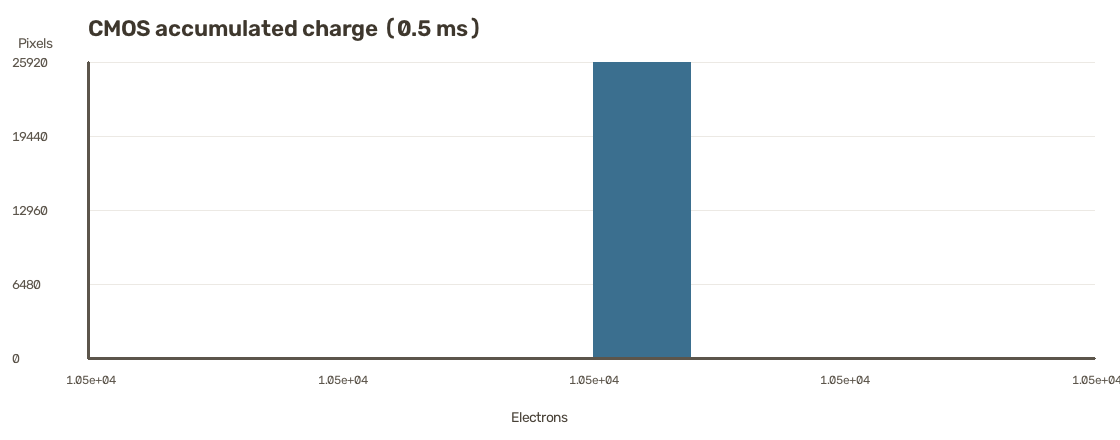

CMOS 0.5 ms: e:\vscode\HVO2\neuron_model\outputs\10-29-14-20-02-380793-HDR\traditional-output\traditional_exposure_underexposed.png; pixels=25920


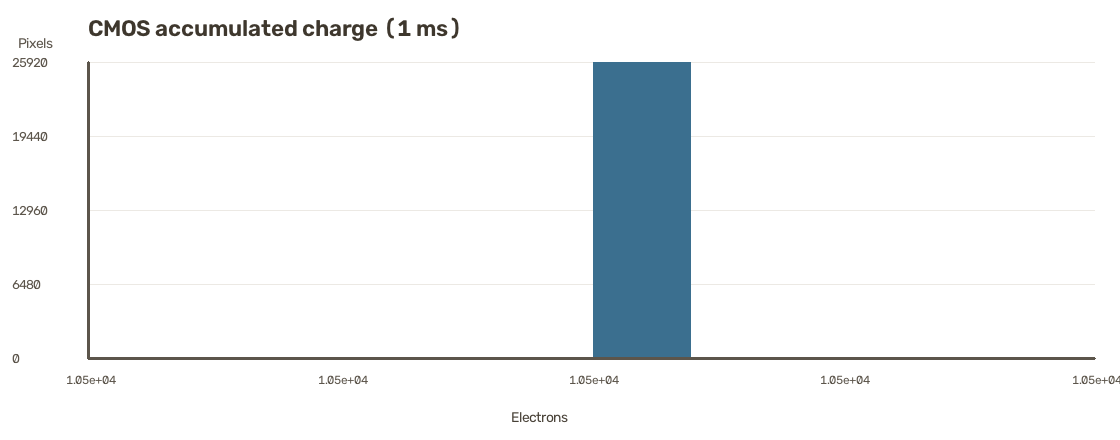

CMOS 1 ms: e:\vscode\HVO2\neuron_model\outputs\10-29-14-20-02-380793-HDR\traditional-output\traditional_exposure_moderate.png; pixels=25920


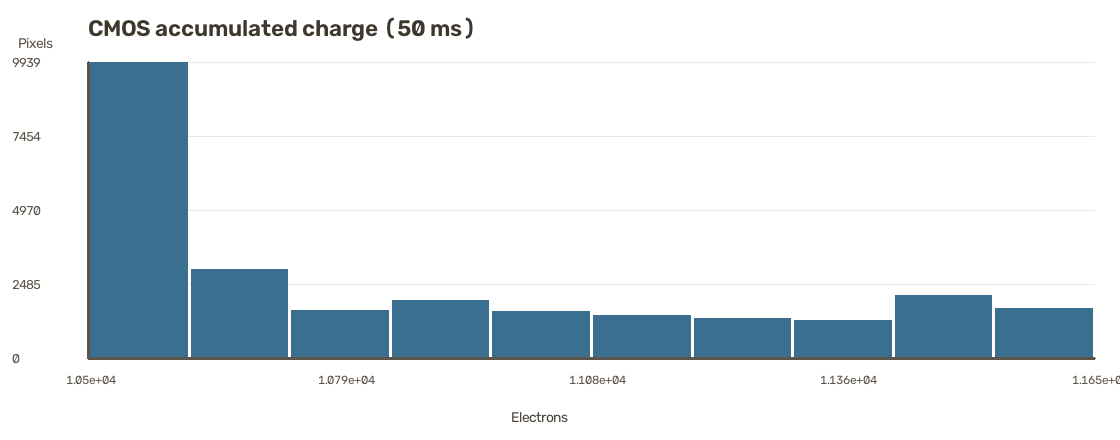

CMOS 50 ms: e:\vscode\HVO2\neuron_model\outputs\10-29-14-20-02-380793-HDR\traditional-output\traditional_exposure_overexposed.png; pixels=25920


In [11]:
CMOS_IMAGES = {}
for label, window_ms in zip(SHUTTER_LABELS, SHUTTER_WINDOWS_MS):
    charge_map = CMOS_CHARGE_MAPS[window_ms]
    image = map_cmos_charge(
        charge_map,
        minimum_charge_electrons=CMOS_MIN_CHARGE_ELECTRONS,
        maximum_charge_electrons=CMOS_MAX_CHARGE_ELECTRONS,
    )
    CMOS_IMAGES[window_ms] = image
    counts = display_histogram(
        charge_map,
        bins=CHARGE_HISTOGRAM_BINS,
        title=f"CMOS accumulated charge ({window_ms:g} ms)",
        x_label="Electrons",
    )
    path = TRADITIONAL_OUTPUT_DIR / f"traditional_exposure_{label}.png"
    if not cv2.imwrite(str(path), image):
        raise OSError(f"failed to save CMOS exposure image: {path}")
    print(f"CMOS {window_ms:g} ms: {path}; pixels={int(counts.sum())}")
